# Week 4-5 — Unsupervised Learning & REST APIs

**Lab: Clustering of Pokemons**

Trong 2 tuần thực hành này, chúng ta làm việc với dữ liệu từ PokeAPI để thu thập thông tin về Pokemons, rồi phân tích bằng các thuật toán clustering:

| Tuần | Nội dung |
|:---:|:---|
| **Tuần 1** | Gọi REST API → Khám phá dữ liệu (EDA) → Feature Extraction → Tiền xử lý |
| **Tuần 2** | KMeans → Elbow & Silhouette → DBSCAN → Hierarchical → Feature Selection → PCA |

## Bài 1: Khám phá PokeAPI

**Mục tiêu:** Gọi endpoint gốc của PokeAPI để xem PokeAPI trả về gì và có bao nhiêu Pokemon.

In [ ]:
import requests
import json

root_url = "https://pokeapi.co/api/v2/"
pokemon_url = "https://pokeapi.co/api/v2/pokemon"

## Bài 2: Thu thập dữ liệu 50 Pokemon đầu tiên

**Mục tiêu:** Viết vòng for để gọi API cho từng Pokemon và thu thập dữ liệu.

**⚠️ Lưu ý:**
- Mỗi Pokemon có endpoint riêng: `/pokemon/{id}`
- Dùng `time.sleep(0.1)` để tránh bị rate-limit API.
- Dùng `try/except` để xử lý lỗi nếu có Pokemon không tồn tại.

**a)** Tạo danh sách rỗng `pokemon_list = []`.

**b)** Vòng for từ 1 đến 50: gọi API, trích xuất thông tin, thêm vào danh sách.

**c)** In số Pokemon đã thu thập được.

In [ ]:
import time

pokemon_list = []
errors = []

# Viet vong for o day:
for pokemon_id in range(1, 51):
    try:
        url = f"https://pokeapi.co/api/v2/pokemon/{pokemon_id}"
        response = requests.get(url)

        if response.status_code == 200:
            pokemon_data = response.json()

            pokemon_info = {
                "id": pokemon_data["id"],
                "name": pokemon_data["name"],
                "height": pokemon_data["height"],
                "weight": pokemon_data["weight"],
                "types": [t["type"]["name"] for t in pokemon_data["types"]]
            }
            pokemon_list.append(pokemon_info)
            print(f"I have taken: {pokemon_data['name']}")
        else:
            errors.append(f"ID {pokemon_id} not found")

    except Exception as e:
        errors.append(e)

    time.sleep(0.1)

print(f"Da thu thap {len(pokemon_list)} Pokemon!")

I have taken: bulbasaur
I have taken: ivysaur
I have taken: venusaur
I have taken: charmander
I have taken: charmeleon
I have taken: charizard
I have taken: squirtle
I have taken: wartortle
I have taken: blastoise
I have taken: caterpie
I have taken: metapod
I have taken: butterfree
I have taken: weedle
I have taken: kakuna
I have taken: beedrill
I have taken: pidgey
I have taken: pidgeotto
I have taken: pidgeot
I have taken: rattata
I have taken: raticate
I have taken: spearow
I have taken: fearow
I have taken: ekans
I have taken: arbok
I have taken: pikachu
I have taken: raichu
I have taken: sandshrew
I have taken: sandslash
I have taken: nidoran-f
I have taken: nidorina
I have taken: nidoqueen
I have taken: nidoran-m
I have taken: nidorino
I have taken: nidoking
I have taken: clefairy
I have taken: clefable
I have taken: vulpix
I have taken: ninetales
I have taken: jigglypuff
I have taken: wigglytuff
I have taken: zubat
I have taken: golbat
I have taken: oddish
I have taken: gloom
I

## Bài 3: Xây dựng DataFrame

**Mục tiêu:** Chuyển danh sách Pokemon thành DataFrame để phân tích.

In [ ]:
import pandas as pd

# Viet code o day:
df = pd.DataFrame(pokemon_list)
df.head()



,id,name,height,weight,types
0,1,bulbasaur,7,69,"[grass, poison]"
1,2,ivysaur,10,130,"[grass, poison]"
2,3,venusaur,20,1000,"[grass, poison]"
3,4,charmander,6,85,[fire]
4,5,charmeleon,11,190,[fire]


## Bài 4: Kiểm tra giá trị missing

**Mục tiêu:** Đếm và xử lý giá trị NaN trong dataset.

In [ ]:
# Viet code o day:
missing_values = df.isnull().sum()
print(missing_values)


id        0
name      0
height    0
weight    0
types     0
dtype: int64


## Bài 5: Thống kê mô tả

**Mục tiêu:** Hiển thị thống kê mô tả và nhận xét về phân bố dữ liệu.

In [ ]:
# Viet code o day:
stats = df[['height','weight']].describe()
display(stats)


,height,weight
count,50.000000,50.000000
mean,9.440000,234.140000
std,5.855958,239.438119
min,2.000000,8.000000
25%,5.250000,71.250000
50%,8.500000,127.500000
75%,11.750000,300.000000
max,35.000000,1000.000000


## Bài 6: Đếm giá trị của cột categorical

**Mục tiêu:** Đếm số Pokemon mỗi type và nhận xét.

In [ ]:
# Viet code o day:
all_types = df.explode('types')
type_counts = all_types['types'].value_counts()
print(type_counts)



types
poison      21
bug         10
normal       9
flying       9
grass        8
fire         5
ground       5
fairy        4
water        3
electric     2
Name: count, dtype: int64


## Bài 7: Vẽ histogram — height và weight

**Mục tiêu:** Trực quan hóa phân bố của height và weight.

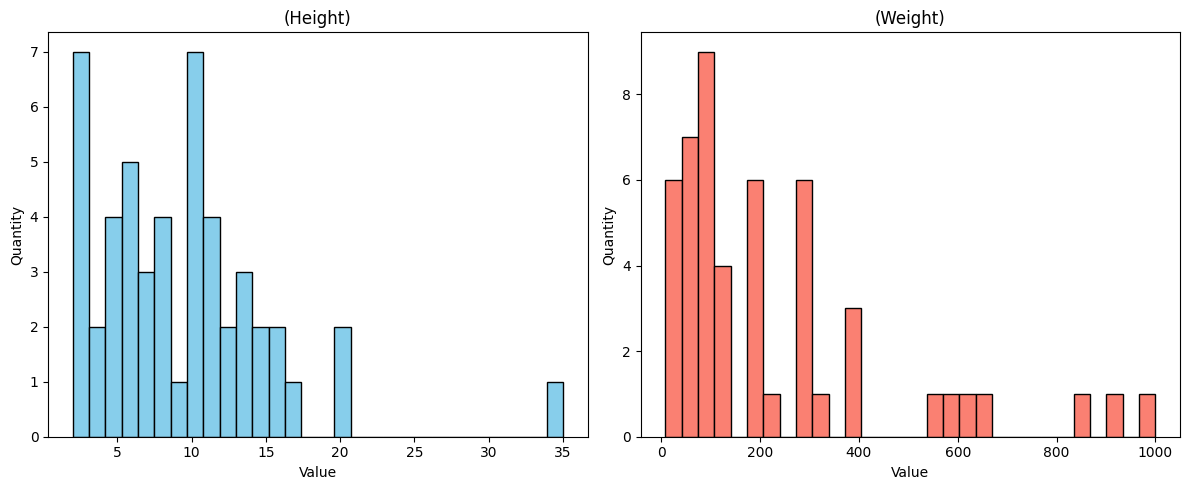

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

# Viet code o day:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Height histogram
axes[0].hist(df['height'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('(Height)')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Quantity')

# Weight histogram
axes[1].hist(df['weight'], bins=30, color='salmon', edgecolor='black')
axes[1].set_title('(Weight)')
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Quantity')

plt.tight_layout()
plt.show()

## Bài 8: Vẽ boxplot — stats theo type

**Mục tiêu:** So sánh stat giữa các type bằng boxplot.

/tmp/ipykernel_572/2424922789.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_types, x='types', y='height', palette='viridis')


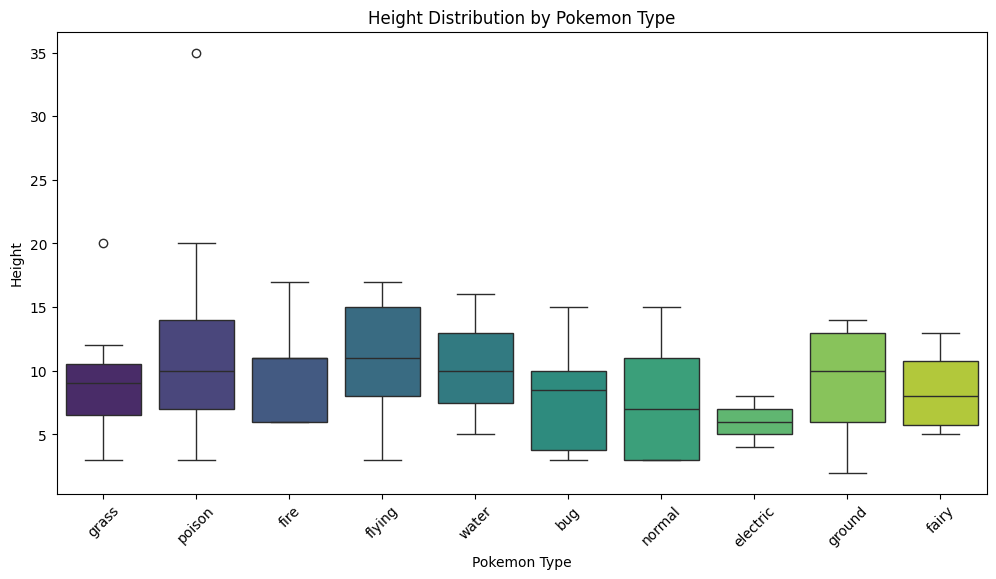

In [ ]:
# Viet code o day:
plt.figure(figsize=(12, 6))
sns.boxplot(data=all_types, x='types', y='height', palette='viridis')

plt.xticks(rotation=45)
plt.title('Height Distribution by Pokemon Type')
plt.xlabel('Pokemon Type')
plt.ylabel('Height')
plt.show()

## Bài 9: Vẽ Correlation Heatmap

**Mục tiêu:** Tính và trực quan hóa ma trận tương quan giữa các thuộc tính.

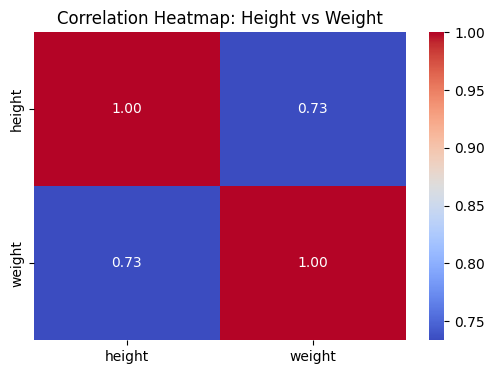

In [ ]:
# Viet code o day:
corr_matrix =df[['height', 'weight']].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap: Height vs Weight')
plt.show()


## Bài 10: Mã hóa cột type (LabelEncoder)

**Mục tiêu:** Chuyển cột `type` (text) thành số để dùng trong clustering.

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Viet code o day:
df['primary_type'] = df['types'].apply(lambda x: x[0])

# Initialize and apply LabelEncoder
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['primary_type'])

# Display encoding mapping
print("Encoding mapping (First 5 rows):")
print(df[['primary_type', 'type_encoded']].head())

Encoding mapping (First 5 rows):
  primary_type  type_encoded
0        grass             4
1        grass             4
2        grass             4
3         fire             3
4         fire             3


## Bài 11: Tách X và chuẩn hóa

**Mục tiêu:** Tách features numeric và chuẩn hóa để clustering không bị thiên lệch.

In [ ]:
# Viet code o day:

# Select features for clustering
X = df[['height', 'weight', 'type_encoded']]

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the data
X_scaled = scaler.fit_transform(X)

print("Standardized Data (First 5 rows):")
print(X_scaled[:5])


Standardized Data (First 5 rows):
[[-0.42089991 -0.69670023 -0.05907962]
 [ 0.09659998 -0.43935062 -0.05907962]
 [ 1.8215996   3.23104538 -0.05907962]
 [-0.59339987 -0.62919869 -0.42832724]
 [ 0.26909994 -0.18621986 -0.42832724]]


## Bài 12: Train KMeans lần đầu (k=3)

**Mục tiêu:** Train KMeans với k=3 và gán nhãn cluster cho từng Pokemon.

Pokemon count per cluster:
cluster
0    24
2    18
1     8
Name: count, dtype: int64


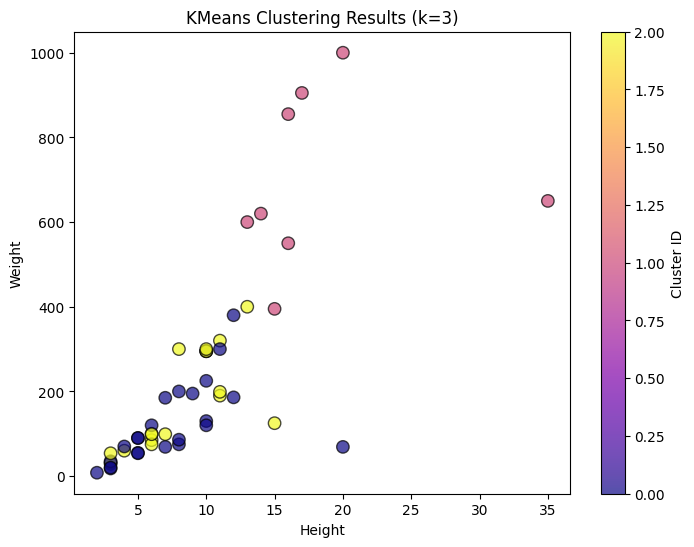

In [ ]:
from sklearn.cluster import KMeans

# Viet code o day:

# Initialize KMeans with k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and predict clusters
df['cluster'] = kmeans.fit_predict(X_scaled)

# Print cluster counts
print("Pokemon count per cluster:")
print(df['cluster'].value_counts())

# Visualize the clusters using Height and Weight
plt.figure(figsize=(8, 6))
plt.scatter(df['height'], df['weight'], c=df['cluster'], cmap='plasma', s=80, edgecolors='black', alpha=0.7)

plt.title('KMeans Clustering Results (k=3)')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.colorbar(label='Cluster ID')
plt.show()

## Bài 13: Trực quan hóa cluster bằng PCA

**Mục tiêu:** Dùng PCA giảm chiều và trực quan hóa các cluster.

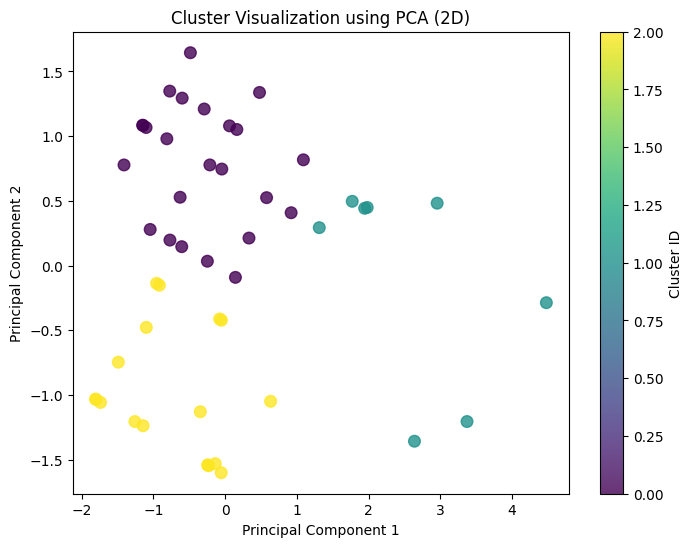

In [ ]:
from sklearn.decomposition import PCA

# Viet code o day:

# Initialize PCA to reduce to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the PCA components with cluster colors
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', s=70, alpha=0.8)
plt.title('Cluster Visualization using PCA (2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster ID')
plt.show()


## Bài 14: Elbow Method — tìm k tối ưu

**Mục tiêu:** Thử nhiều giá trị k và tìm điểm khuỷu tay để chọn k tối ưu.

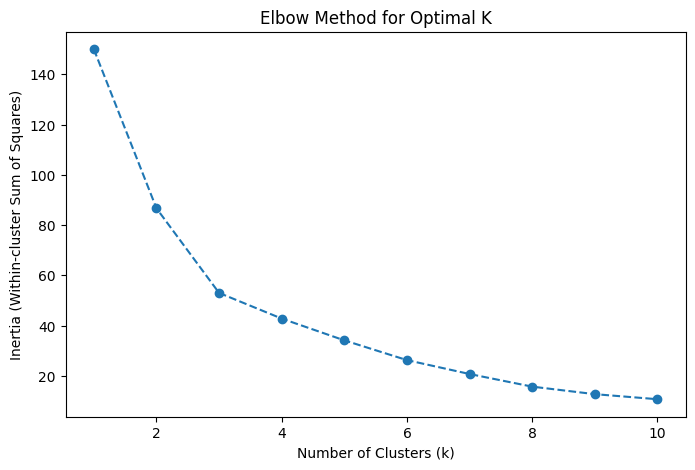

In [ ]:
# Viet code o day:
inertia = []
K_range = range(1, 11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster Sum of Squares)')
plt.show()


## Bài 15: Silhouette Score — đánh giá chất lượng cluster

**Mục tiêu:** Dùng Silhouette score để đánh giá và chọn k tối ưu.

For k=2, Silhouette Score: 0.4873
For k=3, Silhouette Score: 0.3993
For k=4, Silhouette Score: 0.3687
For k=5, Silhouette Score: 0.3824
For k=6, Silhouette Score: 0.3800
For k=7, Silhouette Score: 0.3874
For k=8, Silhouette Score: 0.4124
For k=9, Silhouette Score: 0.4179
For k=10, Silhouette Score: 0.4312


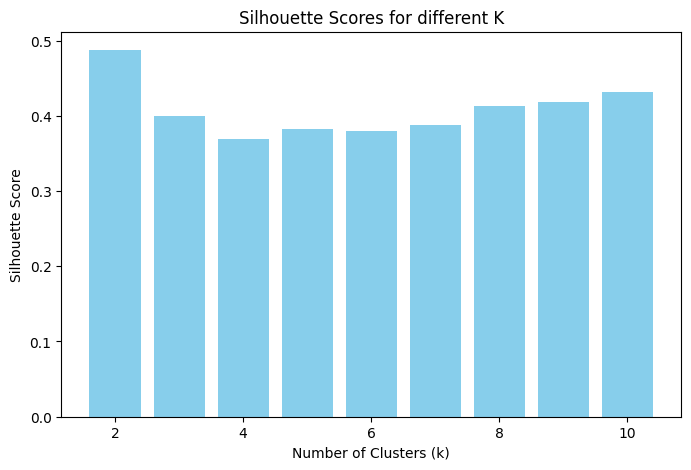

In [ ]:
from sklearn.metrics import silhouette_score

# Viet code o day:
sil_scores = []
K_range = range(2, 11) # Silhouette score requires at least 2 clusters

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"For k={k}, Silhouette Score: {score:.4f}")

# Plotting Silhouette Scores
plt.figure(figsize=(8, 5))
plt.bar(K_range, sil_scores, color='skyblue')
plt.title('Silhouette Scores for different K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()


## Bài 16: DBSCAN Clustering

**Mục tiêu:** So sánh DBSCAN với KMeans.

DBSCAN Cluster Counts (-1 indicates noise):
dbscan_cluster
 0    23
-1    13
 1     4
 2     4
 3     3
 4     3
Name: count, dtype: int64


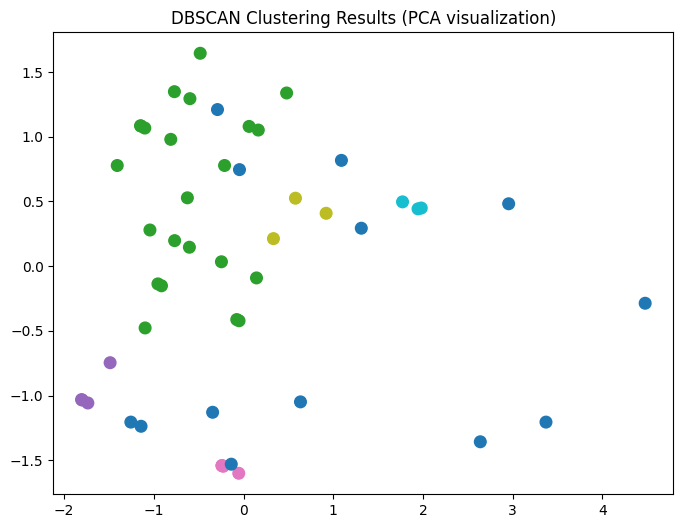

In [ ]:
from sklearn.cluster import DBSCAN

# Viet code o day:

# eps: distance to neighbors, min_samples: min points to form a cluster
dbscan = DBSCAN(eps=0.5, min_samples=3)
db_labels = dbscan.fit_predict(X_scaled)

df['dbscan_cluster'] = db_labels

print("DBSCAN Cluster Counts (-1 indicates noise):")
print(df['dbscan_cluster'].value_counts())

# Visualize DBSCAN results using PCA coordinates
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['dbscan_cluster'], cmap='tab10', s=70)
plt.title('DBSCAN Clustering Results (PCA visualization)')
plt.show()

## Bài 17: Hierarchical Clustering — Dendrogram

**Mục tiêu:** Dùng dendrogram để chọn số cluster phù hợp.

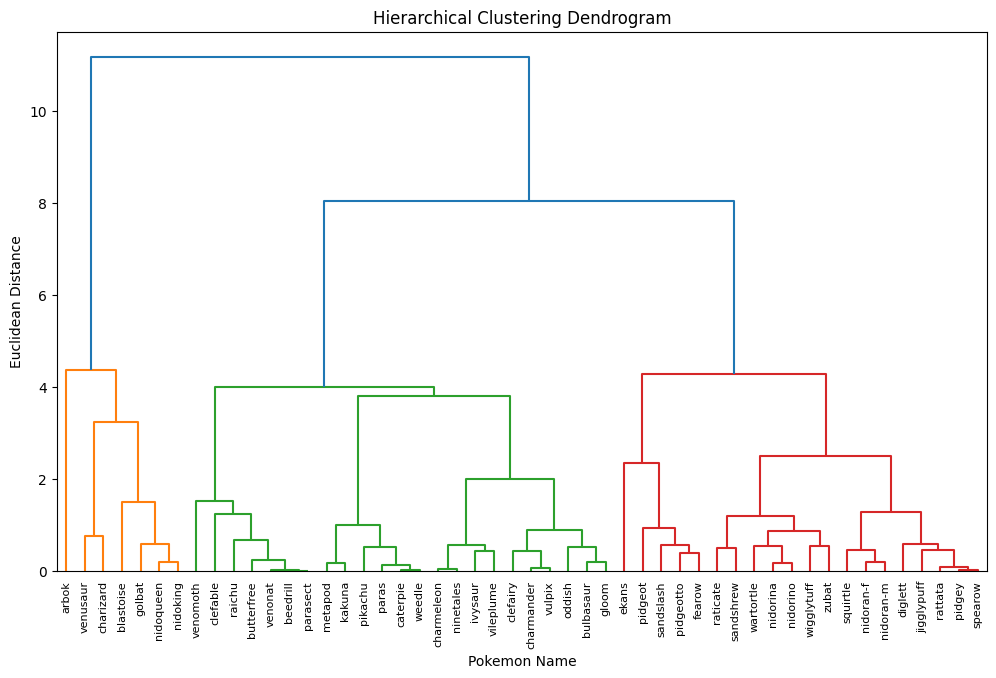

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Viet code o day:

# Compute linkage matrix
Z = linkage(X_scaled, method='ward')

# Plot Dendrogram
plt.figure(figsize=(12, 7))
dendrogram(Z, labels=df['name'].values, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Pokemon Name')
plt.ylabel('Euclidean Distance')
plt.show()


## Bài 18: Chọn features quan trọng nhất bằng PCA

**Mục tiêu:** Dùng PCA để phân tích và chọn số principal components phù hợp.

Explained Variance Ratio per component:
[0.60704451 0.30440504 0.08855045]


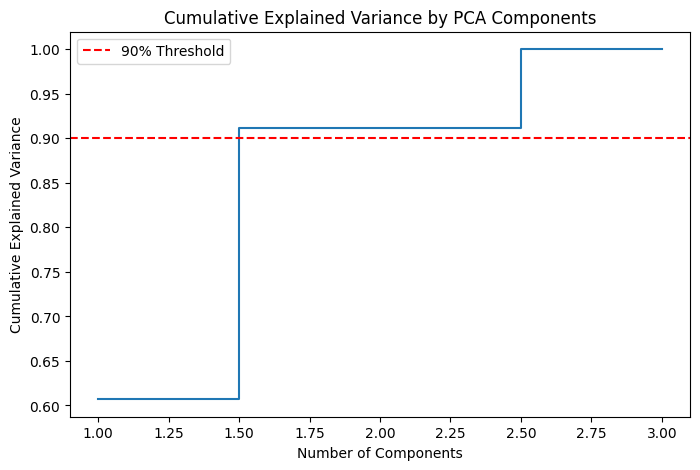

In [ ]:
# Viet code o day:

# Analyze explained variance ratio
pca_full = PCA()
pca_full.fit(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained Variance Ratio per component:")
print(explained_variance)

# Plot Explained Variance
plt.figure(figsize=(8, 5))
plt.step(range(1, len(cumulative_variance)+1), cumulative_variance, where='mid')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.axhline(y=0.9, color='r', linestyle='--', label='90% Threshold')
plt.legend()
plt.show()

## Bài 19: Re-cluster sau khi giảm chiều

**Mục tiêu:** So sánh kết quả clustering trước và sau khi giảm chiều bằng PCA.

Re-clustering completed with k=4
Final Cluster Distribution:
final_cluster
0    18
1    18
3    10
2     4
Name: count, dtype: int64


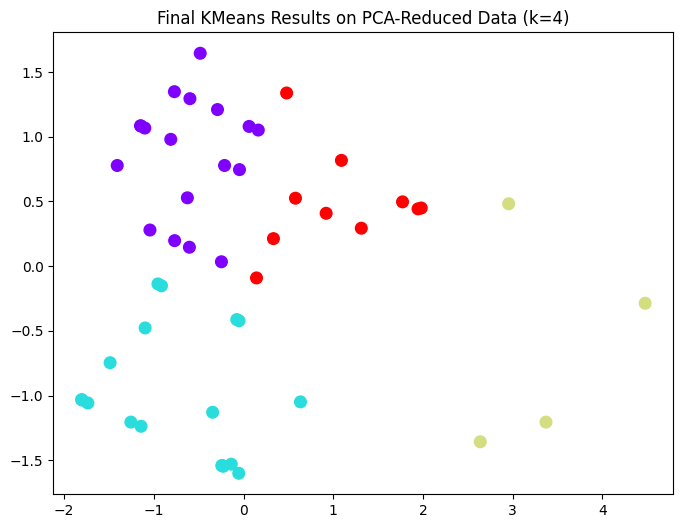

In [ ]:
# Viet code o day:

# Use the first 2 components from PCA for re-clustering
X_reduced = X_pca # Using X_pca from Exercise 13

# Re-run KMeans with the "optimal" K found earlier (let's assume k=4 for example)
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['final_cluster'] = kmeans_final.fit_predict(X_reduced)

print(f"Re-clustering completed with k={optimal_k}")
print("Final Cluster Distribution:")
print(df['final_cluster'].value_counts())

# Visualize final result
plt.figure(figsize=(8, 6))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=df['final_cluster'], cmap='rainbow', s=70)
plt.title(f'Final KMeans Results on PCA-Reduced Data (k={optimal_k})')
plt.show()

---
# PHẦN F — FULL ML PIPELINE

## Bài 20: Full Clustering Pipeline — viết lại từ đầu

**Mục tiêu:** Viết lại toàn bộ pipeline từ bước 1 đến bước cuối, không cần scaffold.

| Bước | Nội dung |
|:---:|:---|
| 1 | Gọi PokeAPI, thu thập 50 Pokemon |
| 2 | Xây dựng DataFrame: id, name, height, weight, type, 6 stats |
| 3 | Kiểm tra & xử lý NaN |
| 4 | Thống kê mô tả |
| 5 | Mã hóa type (LabelEncoder) |
| 6 | Tách X (8 features numeric), StandardScaler |
| 7 | Elbow Method → chọn k |
| 8 | Silhouette Score → chọn k |
| 9 | KMeans với k tối ưu |
| 10 | PCA (2 components) → trực quan hóa |
| 11 | Feature selection — giữ 2 PC đầu |
| 12 | Re-cluster sau PCA → so sánh silhouette |

Starting data collection from PokeAPI...
Collected 10 Pokemons...
Collected 20 Pokemons...
Collected 30 Pokemons...
Collected 40 Pokemons...
Collected 50 Pokemons...
Finished! Total collected: 50

Missing values before cleaning:
id                 0
name               0
height             0
weight             0
type               0
hp                 0
attack             0
defense            0
special-attack     0
special-defense    0
speed              0
dtype: int64

Data cleaning complete. Remaining rows: 50

Descriptive Statistics for Pokemon Stats:


,height,weight,hp,attack,defense,special-attack,special-defense,speed
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.00000,50.000000
mean,9.440000,234.140000,60.040000,64.360000,58.160000,59.040000,60.88000,63.380000
std,5.855958,239.438119,22.230665,19.876927,19.637906,24.448163,22.17338,23.215837
min,2.000000,8.000000,10.000000,20.000000,20.000000,20.000000,20.00000,20.000000
25%,5.250000,71.250000,45.000000,49.250000,43.250000,40.000000,46.25000,45.000000
50%,8.500000,127.500000,60.000000,62.500000,55.000000,57.500000,64.50000,62.500000
75%,11.750000,300.000000,72.250000,80.000000,72.250000,80.000000,79.75000,80.000000
max,35.000000,1000.000000,140.000000,102.000000,110.000000,110.000000,105.00000,110.000000


Sample of encoded types:
         name   type  type_encoded
0   bulbasaur  grass             4
1     ivysaur  grass             4
2    venusaur  grass             4
3  charmander   fire             3
4  charmeleon   fire             3

Feature Scaling Complete.
X_scaled shape: (50, 8)
First row of scaled data:
 [-0.42089991 -0.69670023 -0.68341161 -0.78060068 -0.47118045  0.2462561
  0.18769482 -0.79973871]


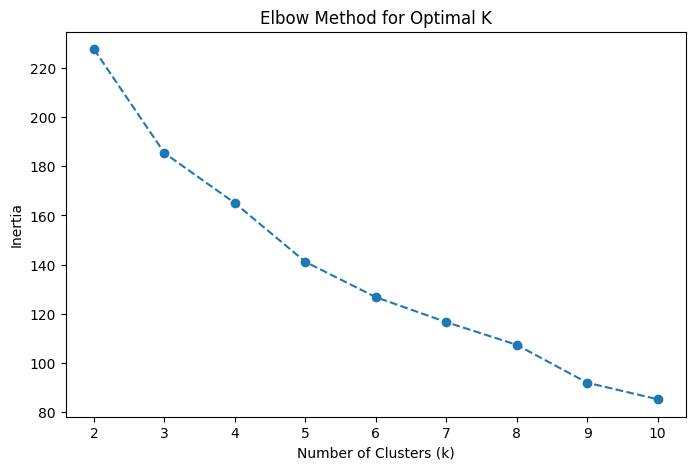

For k=2, Silhouette Score: 0.3461
For k=3, Silhouette Score: 0.2740
For k=4, Silhouette Score: 0.2489
For k=5, Silhouette Score: 0.2154
For k=6, Silhouette Score: 0.2030
For k=7, Silhouette Score: 0.1883
For k=8, Silhouette Score: 0.1813
For k=9, Silhouette Score: 0.2223
For k=10, Silhouette Score: 0.1860

Optimal K based on Silhouette: 2
Clustering complete. Distribution of Pokemons in 2 clusters:
cluster_orig
0    26
1    24
Name: count, dtype: int64


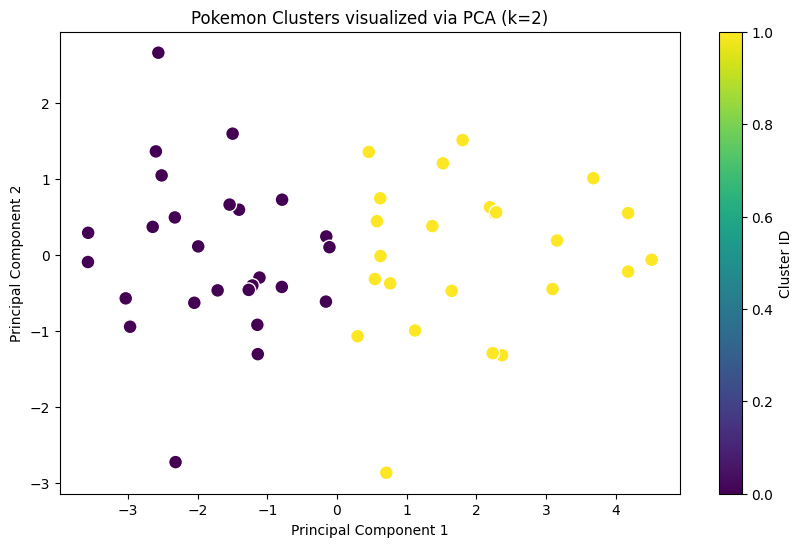

New feature set created from 2 Principal Components.
Shape of reduced data: (50, 2)
----------------------------------------
Silhouette Score (Original 8 features): 0.3461
Silhouette Score (After PCA reduction): 0.4804
----------------------------------------
Insight: Clustering on PCA components yielded clearer, more distinct groups.


In [ ]:
# ============================================================
# BÀI 20 — FULL CLUSTERING PIPELINE
# ============================================================

# ---- Buoc 1: Goi PokeAPI, thu thap 50 Pokemon ----
pokemon_list = []

print("Starting data collection from PokeAPI...")

for i in range(1, 51):
    try:
        response = requests.get(f"https://pokeapi.co/api/v2/pokemon/{i}")
        if response.status_code == 200:
            data = response.json()

            # Extract 6 base stats: hp, attack, defense, special-attack, special-defense, speed
            stats = {s['stat']['name']: s['base_stat'] for s in data['stats']}

            # Combine basic info and stats into one dictionary
            pokemon_info = {
                "id": data["id"],
                "name": data["name"],
                "height": data["height"],
                "weight": data["weight"],
                "type": data["types"][0]["type"]["name"],
                **stats
            }
            pokemon_list.append(pokemon_info)
            if i % 10 == 0:
                print(f"Collected {i} Pokemons...")
    except Exception as e:
        print(f"Error fetching ID {i}: {e}")

    time.sleep(0.05) # Small delay to respect API rate limits

print(f"Finished! Total collected: {len(pokemon_list)}")
# ---- Buoc 2: Xay dung DataFrame ----
df = pd.DataFrame(pokemon_list)
# ---- Buoc 3: Kiem tra & xu ly NaN ----
print("\nMissing values before cleaning:")
print(df.isnull().sum())
features = ['height', 'weight', 'hp', 'attack', 'defense', 'special-attack', 'special-defense', 'speed']
df = df.dropna(subset=features)
print(f"\nData cleaning complete. Remaining rows: {len(df)}")
# ---- Buoc 4: Thong ke mo ta ----
print("\nDescriptive Statistics for Pokemon Stats:")
display(df[features].describe())
# ---- Buoc 5: Ma hoa type (LabelEncoder) ----
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])
print("Sample of encoded types:")
print(df[['name', 'type', 'type_encoded']].head())
# ---- Buoc 6: Tach X (8 features numeric), StandardScaler ----
X = df[features]
# Last defense: double check for any remaining NaN/Inf
X = X.replace([np.inf, -np.inf], np.nan).fillna(X.mean())
# Apply Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nFeature Scaling Complete.")
print("X_scaled shape:", X_scaled.shape)
print("First row of scaled data:\n", X_scaled[0])
# ---- Buoc 7: Elbow Method -> chon k ----
inertia = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()
# ---- Buoc 8: Silhouette Score -> chon k ----
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"For k={k}, Silhouette Score: {score:.4f}")

# Find the k with the highest silhouette score
optimal_k = k_range[np.argmax(sil_scores)]
print(f"\nOptimal K based on Silhouette: {optimal_k}")
# ---- Buoc 9: KMeans voi k toi uu ----
# Train the final model on original scaled data
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster_orig'] = kmeans_final.fit_predict(X_scaled)

print(f"Clustering complete. Distribution of Pokemons in {optimal_k} clusters:")
print(df['cluster_orig'].value_counts())
# ---- Buoc 10: PCA (2 components) -> truc quan hoa ----
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster_orig'], cmap='viridis', s=100, edgecolors='white')
plt.title(f'Pokemon Clusters visualized via PCA (k={optimal_k})')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster ID')
plt.show()
# ---- Buoc 11: Feature selection ----
# Keep the 2D data from PCA
X_reduced = X_pca

print("New feature set created from 2 Principal Components.")
print(f"Shape of reduced data: {X_reduced.shape}")
# ---- Buoc 12: Re-cluster sau PCA -> so sanh silhouette ----
# Re-run KMeans on PCA data
kmeans_pca = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster_pca'] = kmeans_pca.fit_predict(X_reduced)

# Calculate scores
score_orig = silhouette_score(X_scaled, df['cluster_orig'])
score_pca = silhouette_score(X_reduced, df['cluster_pca'])

print("-" * 40)
print(f"Silhouette Score (Original 8 features): {score_orig:.4f}")
print(f"Silhouette Score (After PCA reduction): {score_pca:.4f}")
print("-" * 40)

if score_pca > score_orig:
    print("Insight: Clustering on PCA components yielded clearer, more distinct groups.")
else:
    print("Insight: Using all original features provided better cluster density.")


---

## Bài tập về nhà (Homework)

**1.** Thử thuật toán clustering khác:
   - `SpectralClustering`
   - `GaussianMixture` (GMM — soft clustering)
   So sánh silhouette score với KMeans.

**2.** Thay đổi tham số DBSCAN: thử `eps` từ 0.5 đến 3.0 (bước 0.5), tìm `eps` nào cho kết quả tốt nhất.

**3.** Thu thập thêm dữ liệu: 100 hoặc 200 Pokemon. So sánh kết quả clustering giữa 50 và 200 Pokemon.

**4.** Trực quan hóa cluster bằng pairplot: `sns.pairplot(df[['hp','attack','defense','speed','cluster']], hue='cluster')`.